In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
from config import PREPROCESSED, FIGURES, print_versions
print_versions()

P05 = str(PREPROCESSED)
FIG = str(FIGURES)
FS = 125

SMOOTH_HZ   = 10.0    # lowpass before differentiating
MIN_DIST_MS = 100     # minimum spacing between events
HEIGHT_PCT  = 50      # median of the positive derivative

MIN_DIST = int(round(MIN_DIST_MS / 1000 * FS))
b_lp, a_lp = butter(3, SMOOTH_HZ / (FS / 2), btype="low")

envs, derivs = [], []
for i in range(15):
    env = np.load(os.path.join(P05, f"stim_part{i:02d}.npy"))
    envs.append(env)
    derivs.append(np.maximum(np.gradient(filtfilt(b_lp, a_lp, env)), 0.0))

threshold = float(np.percentile(np.concatenate([d[d > 0] for d in derivs]), HEIGHT_PCT))
print(f"threshold {threshold:.4f}\n")

peakrates = []
for i in range(15):
    idx, props = find_peaks(derivs[i], height=threshold, distance=MIN_DIST)
    pr = np.zeros(len(envs[i]))
    pr[idx] = props["peak_heights"]
    peakrates.append(pr)
    dur = len(envs[i]) / FS
    print(f"part{i:02d}  {len(idx):5d} events  {len(idx)/dur:.2f} per s")

Python 3.12.13 | numpy 2.5.3 | scipy 1.18.1 | sklearn 1.9.0 | mne 1.12.1 | h5py 3.16.0 | matplotlib 3.11.1
threshold 107.1759

part00    539 events  3.32 per s
part01    541 events  3.40 per s
part02    474 events  3.23 per s
part03    492 events  3.43 per s
part04    669 events  3.45 per s
part05    531 events  3.61 per s
part06    620 events  3.36 per s
part07    639 events  3.55 per s
part08    555 events  3.34 per s
part09    653 events  3.58 per s
part10    545 events  3.33 per s
part11    471 events  3.65 per s
part12    401 events  3.43 per s
part13    368 events  3.35 per s
part14    690 events  3.50 per s


In [2]:
import json, glob

ROOT = os.path.dirname(os.path.dirname(P05))
VOWELS = {"AA","AE","AH","AO","AW","AY","EH","ER","EY",
          "IH","IY","OW","OY","UH","UW"}

chapters = [os.path.splitext(os.path.basename(w))[0]
            for w in sorted(glob.glob(os.path.join(ROOT, "audiobooks", "*.wav")))]

n_vow, total_dur = 0, 0
for i, ch in enumerate(chapters):
    with open(os.path.join(ROOT, "audiobooks", f"{ch}_annotations.json")) as f:
        ann = json.load(f)
    v = sum(1 for p in ann["phones"] if p["label"].rstrip("012") in VOWELS)
    n_vow += v
    total_dur += len(envs[i]) / FS

print(f"vowels      {n_vow}   ({n_vow/total_dur:.2f} per s)")
print(f"peakRate    {sum(int((p>0).sum()) for p in peakrates)}   "
      f"({sum(int((p>0).sum()) for p in peakrates)/total_dur:.2f} per s)")

vowels      8874   (3.73 per s)
peakRate    8188   (3.44 per s)


In [3]:
from scipy.stats import zscore, pearsonr

lags = np.arange(-20, 50)          # -160 to 392 ms
ridge_parameter = 1e3
train_parts, val_parts, test_parts = range(9), range(9, 12), range(12, 15)

ch_names = open(os.path.join(P05, "ch_names.txt")).read().split()

eegs, prs = [], []
for i in range(15):
    e = np.load(os.path.join(P05, f"eeg_part{i:02d}.npy"))
    n = min(e.shape[1], len(peakrates[i]))
    eegs.append(zscore(e[:, :n], axis=1))
    prs.append(zscore(peakrates[i][:n]))

def lag_chapter(s, eeg, lags):
    """Lagged feature and matching EEG for one chapter, edge samples discarded."""
    n = len(s)
    t0, t1 = lags.max(), n + lags.min()          # samples with every lag available
    X = np.vstack([s[t0 - L : t1 - L] for L in lags])
    return X, eeg[:, t0:t1]

def design(parts):
    Xs, Ys = zip(*(lag_chapter(prs[i], eegs[i], lags) for i in parts))
    return np.hstack(Xs), np.hstack(Ys)

Xtr, tr_eeg = design(train_parts)
Xte, te_eeg = design(test_parts)

coef = np.linalg.solve(Xtr @ Xtr.T + ridge_parameter * np.eye(Xtr.shape[0]),
                       Xtr @ tr_eeg.T)
pred = Xte.T @ coef

r = np.array([pearsonr(pred[:, c], te_eeg[c])[0] for c in range(63)])
print(f"peakRate  test mean r {r.mean():.4f}   highest test r {r.max():.4f} at {ch_names[r.argmax()]}")
for c in np.argsort(r)[::-1][:5]:
    print(f"  {ch_names[c]:>5}  {r[c]:.4f}")

peakRate  test mean r 0.0369   highest test r 0.0929 at FC3
    FC3  0.0929
    FCz  0.0888
    FC1  0.0833
    FC5  0.0829
    FC2  0.0724


In [4]:
# channel chosen on the validation chapters

Xva, va_eeg = design(val_parts)
pv = Xva.T @ coef
r_val = np.array([pearsonr(pv[:, k], va_eeg[k])[0] for k in range(63)])
best = r_val.argmax()
print(f"best on validation: {ch_names[best]} (val r {r_val[best]:.4f}, test r {r[best]:.4f})")
print(f"test mean r {r.mean():.4f}")

best on validation: FC5 (val r 0.1088, test r 0.0829)
test mean r 0.0369


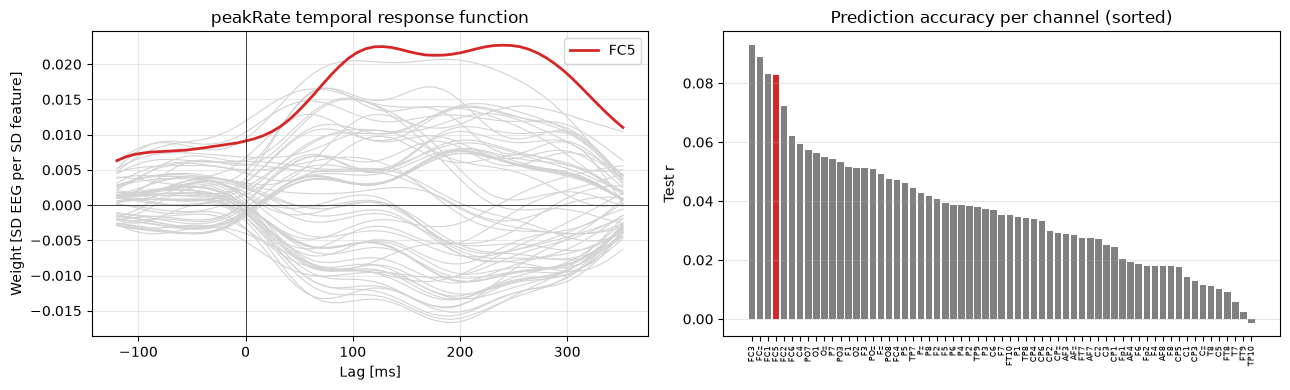

In [5]:
#TRF at all channels and accuracy per channel ---
t_ms = lags / FS * 1000
keep = slice(5, len(lags) - 5)
c = best                                   # channel chosen on validation (cell A)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))

axs[0].plot(t_ms[keep], coef[keep, :], c='lightgrey', lw=0.8)
axs[0].plot(t_ms[keep], coef[keep, c], c='tab:red', lw=2, label=ch_names[c])
axs[0].axhline(0, c='k', lw=0.5); axs[0].axvline(0, c='k', lw=0.5)
axs[0].set_xlabel('Lag [ms]'); axs[0].set_ylabel('Weight [SD EEG per SD feature]')
axs[0].set_title('peakRate temporal response function'); axs[0].legend()
axs[0].grid(True, alpha=0.3)

order = np.argsort(r)[::-1]
axs[1].bar(range(63), r[order], color=['tab:red' if k == c else 'grey' for k in order])
axs[1].set_xticks(range(63))
axs[1].set_xticklabels([ch_names[i] for i in order], rotation=90, fontsize=6)
axs[1].set_ylabel('Test r'); axs[1].set_title('Prediction accuracy per channel (sorted)')
axs[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG, "pr_trf.pdf"), bbox_inches="tight")

In [6]:
# TRF peaks and troughs at the chosen channel ---
w, tk = coef[keep, best], t_ms[keep]
for p in find_peaks(w)[0]:  print(f"peak   {tk[p]:4.0f} ms   weight {w[p]:.4f}")
for p in find_peaks(-w)[0]: print(f"trough {tk[p]:4.0f} ms   weight {w[p]:.4f}")
print(f"negative lags: mean {w[tk < 0].mean():.4f}   min {w[tk < 0].min():.4f}   max {w[tk < 0].max():.4f}")

peak    128 ms   weight 0.0225
peak    240 ms   weight 0.0227
trough  176 ms   weight 0.0213
negative lags: mean 0.0078   min 0.0063   max 0.0088


In [7]:
# circular-shift null and corrected threshold ---
lens = [len(prs[i]) + lags.min() - lags.max() for i in test_parts]
bounds = np.cumsum([0] + lens)
rng = np.random.default_rng(0)
N_NULL = 1000
pz = zscore(pred, axis=0)
null_r = np.empty((N_NULL, 63))
for j in range(N_NULL):
    shifted = np.hstack([np.roll(te_eeg[:, i0:i1], rng.integers(10*FS, (i1 - i0) - 10*FS), axis=1)
                         for i0, i1 in zip(bounds[:-1], bounds[1:])])
    null_r[j] = (pz * zscore(shifted, axis=1).T).mean(axis=0)

for name, obs, null in [(ch_names[best], r[best], null_r[:, best]),
                        ("mean", r.mean(), null_r.mean(axis=1))]:
    p = ((null >= obs).sum() + 1) / (N_NULL + 1)
    print(f"{name:>5}  observed {obs:.4f}   null mean {null.mean():.4f}   "
          f"95th {np.percentile(null, 95):.4f}   p = {p:.4f}")

thr = np.percentile(null_r.max(axis=1), 95)
sig = r > thr
print(f"\ncorrected threshold {thr:.4f}: " + ", ".join(f"{ch_names[k]} {r[k]:.4f}" for k in np.flatnonzero(sig)))

  FC5  observed 0.0829   null mean -0.0006   95th 0.0368   p = 0.0010
 mean  observed 0.0369   null mean -0.0001   95th 0.0199   p = 0.0010

corrected threshold 0.0572: C4 0.0592, FC1 0.0833, FC2 0.0724, FC3 0.0929, FC5 0.0829, FC6 0.0621, PO7 0.0574, FCz 0.0888


PO7 weight at 128 and 240 ms: [-0.01304104 -0.01375689]


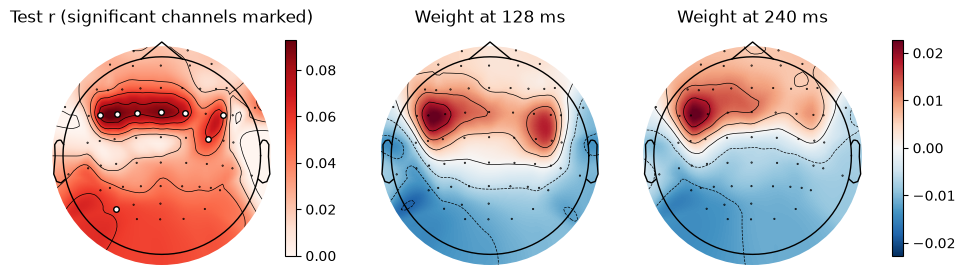

In [8]:
# scalp maps of accuracy and TRF weights at the two largest peaks ---
import mne

info = mne.create_info(ch_names, FS, ch_types='eeg')
info.set_montage('standard_1005')
pk = find_peaks(w)[0]
ks = sorted(pk[np.argsort(w[pk])[::-1][:2]] + keep.start)
v = np.abs(coef[ks, :]).max()

fig, axs = plt.subplots(1, 1 + len(ks), figsize=(4 * (1 + len(ks)), 4))
im0, _ = mne.viz.plot_topomap(r, info, axes=axs[0], cmap='Reds', vlim=(0, r.max()), mask=sig, show=False)
axs[0].set_title('Test r (significant channels marked)')
for ax, k in zip(axs[1:], ks):
    im, _ = mne.viz.plot_topomap(coef[k], info, axes=ax, cmap='RdBu_r', vlim=(-v, v), show=False)
    ax.set_title(f'Weight at {t_ms[k]:.0f} ms')
fig.colorbar(im0, ax=axs[0], shrink=0.7); fig.colorbar(im, ax=list(axs[1:]), shrink=0.7)
plt.savefig(os.path.join(FIG, "pr_topo.pdf"), bbox_inches="tight")

print(f"PO7 weight at {t_ms[ks[0]]:.0f} and {t_ms[ks[1]]:.0f} ms: {coef[ks, ch_names.index('PO7')]}")

In [9]:
EPOCH_MS = (-200, 500)
BASE_MS  = (-200, 0)

s0, s1 = [int(round(m / 1000 * FS)) for m in EPOCH_MS]
b0, b1 = [int(round(m / 1000 * FS)) - s0 for m in BASE_MS]
t_ep = np.arange(s0, s1) / FS * 1000

epochs = []
for i in range(15):
    eeg_uv = np.load(os.path.join(P05, f"eeg_part{i:02d}.npy"))    # microvolts
    for k in np.flatnonzero(peakrates[i]):
        i0, i1 = k + s0, k + s1
        if i0 < 0 or i1 > eeg_uv.shape[1]:
            continue
        ep = eeg_uv[:, i0:i1]
        epochs.append(ep - ep[:, b0:b1].mean(axis=1, keepdims=True))

epochs = np.array(epochs)          # (n_events, 63, n_times)
erp = epochs.mean(axis=0)
print(f"{epochs.shape[0]} epochs, {epochs.shape[2]} samples each")

8188 epochs, 87 samples each


In [10]:
# --- split events: after a pause vs within ongoing speech ---
import json, glob
from collections import Counter

ROOT = os.path.dirname(os.path.dirname(P05))
AUD = os.path.join(ROOT, "audiobooks")
chapters = [os.path.splitext(os.path.basename(w))[0]
            for w in sorted(glob.glob(os.path.join(AUD, "*.wav")))]

def phones(ch):
    with open(os.path.join(AUD, f"{ch}_annotations.json")) as f:
        return json.load(f)["phones"]

PAUSE_LABELS = {"sil", "sp", ""}     # "spn" is unrecognised speech, not silence
MIN_PAUSE_MS = 300                   # shortest interval counted as a pause
TOL = 0.05                           # s; an event may lead its vowel onset slightly

print(Counter(p["label"].strip().lower() for ch in chapters for p in phones(ch)
              if p["label"].strip().lower() in {"sil", "sp", "spn", ""}), "\n")

def split_events(min_pause_ms):
    groups = []
    for i, ch in enumerate(chapters):
        sil = [(p["start"], p["end"]) for p in phones(ch)
               if p["label"].strip().lower() in PAUSE_LABELS]
        long_sil = [(a, z) for a, z in sil if (z - a) * 1000 >= min_pause_ms]
        g, prev = [], -np.inf
        for t in np.flatnonzero(peakrates[i]) / FS:
            if any(a + TOL < t < z - TOL for a, z in sil):
                g.append("inside")                     # e.g. a breath during a pause
                continue
            after = any(prev <= a + TOL and z <= t + TOL for a, z in long_sil)
            g.append("pause" if after else "ongoing")
            prev = t
        groups.append(np.array(g))
    return groups

for mp in (200, 300, 500):
    gs = np.concatenate(split_events(mp))
    print(f"pause >= {mp} ms:  after pause {(gs == 'pause').sum():4d}   "
          f"ongoing {(gs == 'ongoing').sum():4d}   inside a pause {(gs == 'inside').sum():3d}")

group = split_events(MIN_PAUSE_MS)

print()
ratios = []
for i in range(15):
    mag = peakrates[i][np.flatnonzero(peakrates[i])]
    m_p, m_o = np.median(mag[group[i] == "pause"]), np.median(mag[group[i] == "ongoing"])
    ratios.append(m_p / m_o)
    print(f"part{i:02d}  after pause {(group[i] == 'pause').sum():4d}   "
          f"median mag  pause {m_p:6.1f}  ongoing {m_o:6.1f}")
print(f"after-pause events steeper by {(min(ratios)-1)*100:.0f} to {(max(ratios)-1)*100:.0f}%")

Counter({'': 810, 'sil': 30}) 

pause >= 200 ms:  after pause  577   ongoing 7611   inside a pause   0
pause >= 300 ms:  after pause  456   ongoing 7732   inside a pause   0
pause >= 500 ms:  after pause  316   ongoing 7872   inside a pause   0

part00  after pause   29   median mag  pause  677.7  ongoing  349.0
part01  after pause   28   median mag  pause  560.2  ongoing  369.7
part02  after pause   34   median mag  pause  590.2  ongoing  365.6
part03  after pause   22   median mag  pause  629.6  ongoing  408.4
part04  after pause   34   median mag  pause  661.4  ongoing  417.6
part05  after pause   19   median mag  pause  510.5  ongoing  370.3
part06  after pause   33   median mag  pause  689.6  ongoing  430.3
part07  after pause   34   median mag  pause  643.9  ongoing  417.1
part08  after pause   31   median mag  pause  680.5  ongoing  379.8
part09  after pause   36   median mag  pause  489.3  ongoing  393.1
part10  after pause   37   median mag  pause  572.2  ongoing  367.0
part11

  after a pause  peak   -168 ms  +0.104 µV
  after a pause  peak    224 ms  +1.710 µV
  after a pause  peak    472 ms  +1.576 µV
  after a pause  trough  -32 ms  -0.186 µV
  after a pause  trough  400 ms  +1.473 µV
  after a pause  at 488 ms  +1.573 µV
 ongoing speech  peak    -48 ms  +0.042 µV
 ongoing speech  peak     88 ms  +0.138 µV
 ongoing speech  peak    240 ms  +0.067 µV
 ongoing speech  trough    0 ms  +0.026 µV
 ongoing speech  trough  176 ms  +0.043 µV
 ongoing speech  at 488 ms  -0.126 µV


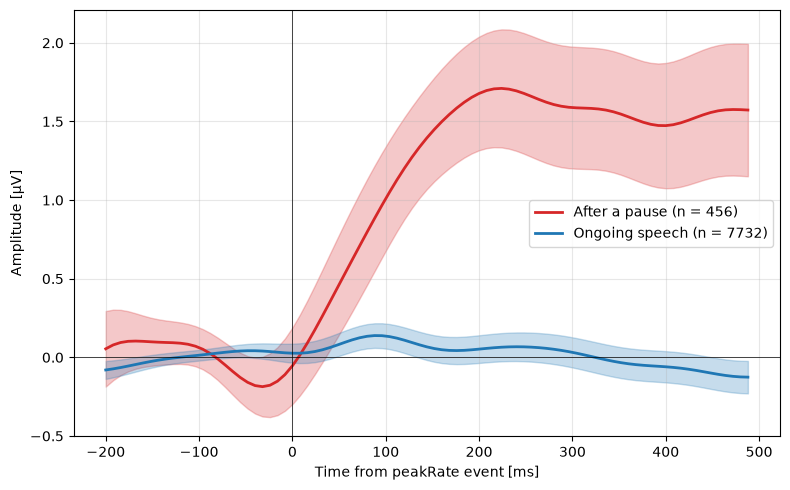

In [11]:
# --- average response after a pause and within ongoing speech ---
on_ep, ong_ep, on_mag, ong_mag = [], [], [], []
for i in range(15):
    eeg_uv = np.load(os.path.join(P05, f"eeg_part{i:02d}.npy"))
    for idx, g in zip(np.flatnonzero(peakrates[i]), group[i]):
        if g == "inside":
            continue
        i0, i1 = idx + s0, idx + s1
        if i0 < 0 or i1 > eeg_uv.shape[1]:
            continue
        ep = eeg_uv[:, i0:i1]
        ep = ep - ep[:, b0:b1].mean(axis=1, keepdims=True)
        (on_ep if g == "pause" else ong_ep).append(ep)
        (on_mag if g == "pause" else ong_mag).append(peakrates[i][idx])

on_ep, ong_ep = np.array(on_ep), np.array(ong_ep)
ci = best

plt.figure(figsize=(8, 5))
for e, name, col in [(on_ep, 'After a pause', 'tab:red'),
                     (ong_ep, 'Ongoing speech', 'tab:blue')]:
    m = e[:, ci].mean(axis=0)
    s = e[:, ci].std(axis=0) / np.sqrt(len(e))
    plt.plot(t_ep, m, c=col, lw=2, label=f'{name} (n = {len(e)})')
    plt.fill_between(t_ep, m - 1.96*s, m + 1.96*s, color=col, alpha=0.25)

plt.axhline(0, c='k', lw=0.5); plt.axvline(0, c='k', lw=0.5)
plt.xlabel('Time from peakRate event [ms]'); plt.ylabel('Amplitude [µV]')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "pr_context.pdf"), bbox_inches="tight")

for e, name in [(on_ep, 'after a pause'), (ong_ep, 'ongoing speech')]:
    m = e[:, ci].mean(axis=0)
    for p in find_peaks(m)[0]:  print(f"{name:>15}  peak   {t_ep[p]:4.0f} ms  {m[p]:+.3f} µV")
    for p in find_peaks(-m)[0]: print(f"{name:>15}  trough {t_ep[p]:4.0f} ms  {m[p]:+.3f} µV")
    print(f"{name:>15}  at {t_ep[-1]:.0f} ms  {m[-1]:+.3f} µV")

In [12]:
# --- checks for the pause split ---
# 1. how long after the end of the pause does the event come?
delay = []
for i, ch in enumerate(chapters):
    ends = np.array([p["end"] for p in phones(ch)
                     if p["label"].strip().lower() in PAUSE_LABELS
                     and (p["end"] - p["start"]) * 1000 >= MIN_PAUSE_MS])
    for t in np.flatnonzero(peakrates[i])[group[i] == "pause"] / FS:
        delay.append((t - ends[ends <= t + TOL].max()) * 1000)
delay = np.array(delay)
print(f"event after end of pause: median {np.median(delay):.0f} ms, "
      f"IQR {np.percentile(delay, 25):.0f}-{np.percentile(delay, 75):.0f} ms\n")

# 2. does the result depend on the 300 ms choice?
for mp in (200, 300, 500):
    g_all, ep = split_events(mp), []
    for i in range(15):
        eeg_uv = np.load(os.path.join(P05, f"eeg_part{i:02d}.npy"))
        for idx in np.flatnonzero(peakrates[i])[g_all[i] == "pause"]:
            if idx + s0 < 0 or idx + s1 > eeg_uv.shape[1]:
                continue
            x = eeg_uv[ci, idx + s0: idx + s1]
            ep.append(x - x[b0:b1].mean())
    m = np.mean(ep, axis=0); k = np.argmax(m)
    print(f"pause >= {mp} ms:  n {len(ep):3d}   peak {m[k]:+.2f} µV at {t_ep[k]:.0f} ms")

# 3. how much of the pooled response does each group carry?
n_all = len(on_ep) + len(ong_ep)
print()
for t in (96, 240):
    k = np.argmin(np.abs(t_ep - t))
    part_p = on_ep[:, ci, k].mean() * len(on_ep) / n_all
    part_o = ong_ep[:, ci, k].mean() * len(ong_ep) / n_all
    print(f"{t} ms: pooled {part_p + part_o:+.3f} µV = after pause {part_p:+.3f} + ongoing {part_o:+.3f}   "
          f"({part_p / (part_p + part_o) * 100:.0f}% from {len(on_ep) / n_all * 100:.1f}% of events)")

event after end of pause: median 89 ms, IQR 64-132 ms

pause >= 200 ms:  n 577   peak +1.69 µV at 224 ms
pause >= 300 ms:  n 456   peak +1.71 µV at 224 ms
pause >= 500 ms:  n 316   peak +1.70 µV at 240 ms

96 ms: pooled +0.184 µV = after pause +0.054 + ongoing +0.130   (29% from 5.6% of events)
240 ms: pooled +0.158 µV = after pause +0.094 + ongoing +0.064   (60% from 5.6% of events)


Q1  n=1547  median mag  159.8  peak 30-150 ms 0.106 µV
Q2  n=1546  median mag  269.9  peak 30-150 ms 0.172 µV
Q3  n=1546  median mag  388.1  peak 30-150 ms 0.207 µV
Q4  n=1546  median mag  521.9  peak 30-150 ms 0.092 µV
Q5  n=1547  median mag  727.5  peak 30-150 ms 0.190 µV

largest spread between groups before the event: 0.187 µV


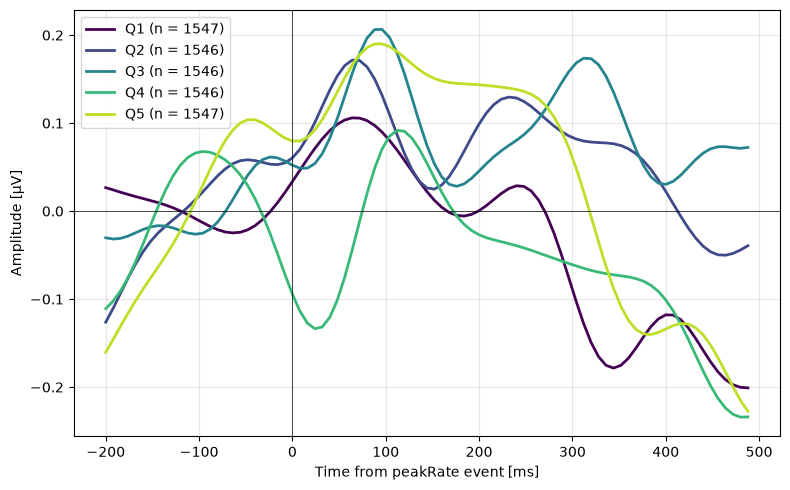

In [13]:
# --- ongoing-speech response by magnitude group ---
ong_mag = np.array(ong_mag)
edges = np.percentile(ong_mag, [20, 40, 60, 80])
q = np.searchsorted(edges, ong_mag, side='right')

ci = best
colors = plt.cm.viridis(np.linspace(0, 0.9, 5))

plt.figure(figsize=(8, 5))
means = []
for k in range(5):
    e = ong_ep[q == k]
    m = e[:, ci].mean(axis=0)
    means.append(m)
    plt.plot(t_ep, m, color=colors[k], lw=2, label=f'Q{k+1} (n = {len(e)})')

plt.axhline(0, c='k', lw=0.5); plt.axvline(0, c='k', lw=0.5)
plt.xlabel('Time from peakRate event [ms]'); plt.ylabel('Amplitude [µV]')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "pr_quantiles.pdf"), bbox_inches="tight")

win = (t_ep > 30) & (t_ep < 150)
for k in range(5):
    print(f"Q{k+1}  n={(q == k).sum():4d}  median mag {np.median(ong_mag[q == k]):6.1f}  "
          f"peak 30-150 ms {means[k][win].max():.3f} µV")

means = np.array(means)
pre = t_ep < 0
print(f"\nlargest spread between groups before the event: "
      f"{(means[:, pre].max(axis=0) - means[:, pre].min(axis=0)).max():.3f} µV")

threshold 2077.8
peakEnv  8188 events
peakRate 8188 events
 peakRate  at 0 ms  +0.022 µV
 peakRate  peak    -56 ms  +0.031 µV
 peakRate  peak     96 ms  +0.184 µV
 peakRate  peak    240 ms  +0.158 µV
  peakEnv  at 0 ms  +0.054 µV
  peakEnv  peak    -96 ms  +0.032 µV
  peakEnv  peak     56 ms  +0.148 µV
  peakEnv  peak    232 ms  +0.113 µV
  peakEnv  peak    368 ms  +0.029 µV


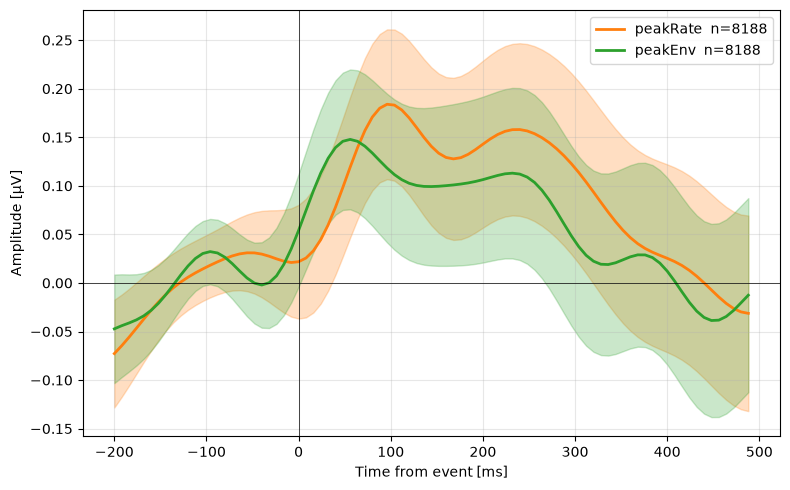

In [14]:
target = sum(int((p > 0).sum()) for p in peakrates)

heights = []
for i in range(15):
    env_s = filtfilt(b_lp, a_lp, envs[i])
    idx, _ = find_peaks(env_s, distance=MIN_DIST)
    heights.append(env_s[idx])
th_env = float(np.sort(np.concatenate(heights))[-target])

peakenvs = []
for i in range(15):
    env_s = filtfilt(b_lp, a_lp, envs[i])
    idx, _ = find_peaks(env_s, height=th_env, distance=MIN_DIST)
    pe = np.zeros(len(envs[i]))
    pe[idx] = env_s[idx]
    peakenvs.append(pe)

print(f"threshold {th_env:.1f}")
print(f"peakEnv  {sum(int((p>0).sum()) for p in peakenvs)} events")
print(f"peakRate {target} events")

def erp_at(events, ci):
    out = []
    for i in range(15):
        eeg_uv = np.load(os.path.join(P05, f"eeg_part{i:02d}.npy"))
        for k in np.flatnonzero(events[i]):
            aa, bb = k + s0, k + s1
            if aa < 0 or bb > eeg_uv.shape[1]:
                continue
            ep = eeg_uv[ci, aa:bb]
            out.append(ep - ep[b0:b1].mean())
    return np.array(out)

ci = best
pr_e, pe_e = erp_at(peakrates, ci), erp_at(peakenvs, ci)

plt.figure(figsize=(8, 5))
for e, name, col in [(pr_e, 'peakRate', 'tab:orange'), (pe_e, 'peakEnv', 'tab:green')]:
    m, s = e.mean(axis=0), e.std(axis=0) / np.sqrt(len(e))
    plt.plot(t_ep, m, c=col, lw=2, label=f'{name}  n={len(e)}')
    plt.fill_between(t_ep, m - 1.96*s, m + 1.96*s, color=col, alpha=0.25)

plt.axhline(0, c='k', lw=0.5); plt.axvline(0, c='k', lw=0.5)
plt.xlabel('Time from event [ms]'); plt.ylabel('Amplitude [µV]')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "pr_vs_env.pdf"), bbox_inches="tight")

for e, name in [(pr_e, 'peakRate'), (pe_e, 'peakEnv')]:
    m = e.mean(axis=0)
    print(f"{name:>9}  at 0 ms  {m[t_ep == 0][0]:+.3f} µV")
    for p in find_peaks(m)[0]:  print(f"{name:>9}  peak   {t_ep[p]:4.0f} ms  {m[p]:+.3f} µV")

In [15]:
gaps = []
for i in range(15):
    pr = np.flatnonzero(peakrates[i])
    pe = np.flatnonzero(peakenvs[i])
    for k in pr:
        nxt = pe[pe > k]
        if len(nxt):
            gaps.append((nxt[0] - k) / FS * 1000)
gaps = np.array(gaps)
print(f"peakRate to next peakEnv: median {np.median(gaps):.0f} ms, "
      f"IQR {np.percentile(gaps,25):.0f}-{np.percentile(gaps,75):.0f} ms")

peakRate to next peakEnv: median 40 ms, IQR 32-64 ms


     vowel  median   -6.0 ms   SD  56.9   within 50 ms: 77.6%
 consonant  median   -6.0 ms   SD  72.9   within 50 ms: 48.6%


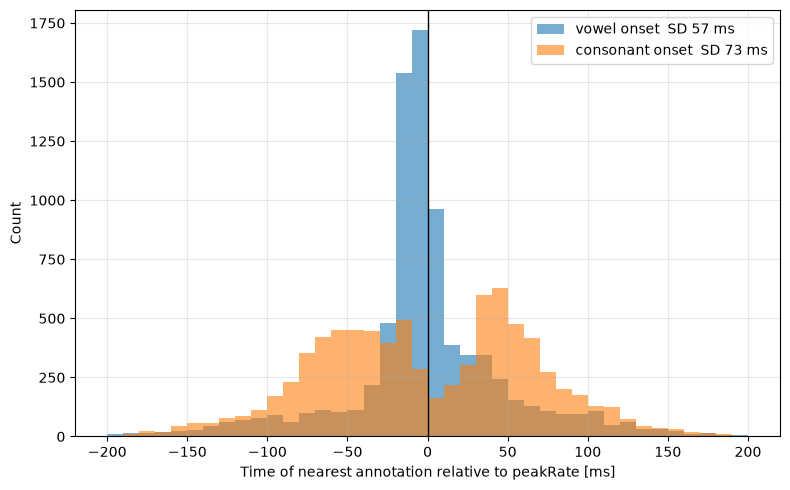

In [16]:
import json, glob

VOWELS = {"AA","AE","AH","AO","AW","AY","EH","ER","EY",
          "IH","IY","OW","OY","UH","UW"}
chapters = [os.path.splitext(os.path.basename(w))[0]
            for w in sorted(glob.glob(os.path.join(ROOT, "audiobooks", "*.wav")))]

d_vow, d_syl = [], []
for i, ch in enumerate(chapters):
    with open(os.path.join(ROOT, "audiobooks", f"{ch}_annotations.json")) as f:
        ph = json.load(f)["phones"]

    vow = np.array([p["start"] for p in ph if p["label"].rstrip("012") in VOWELS])
    syl = np.array([p["start"] for p in ph
                if p["label"].strip()
                and p["label"].strip().lower() not in {"sil", "sp", "spn"}
                and p["label"].rstrip("012") not in VOWELS])

    for k in np.flatnonzero(peakrates[i]):
        t = k / FS
        if len(vow): d_vow.append((vow[np.argmin(np.abs(vow - t))] - t) * 1000)
        if len(syl): d_syl.append((syl[np.argmin(np.abs(syl - t))] - t) * 1000)

d_vow, d_syl = np.array(d_vow), np.array(d_syl)

plt.figure(figsize=(8, 5))
bins = np.arange(-200, 205, 10)
plt.hist(d_vow, bins=bins, alpha=0.6, label=f'vowel onset  SD {d_vow.std():.0f} ms')
plt.hist(d_syl, bins=bins, alpha=0.6, label=f'consonant onset  SD {d_syl.std():.0f} ms')
plt.axvline(0, c='k', lw=1)
plt.xlabel('Time of nearest annotation relative to peakRate [ms]')
plt.ylabel('Count'); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "pr_alignment.pdf"), bbox_inches="tight")

for name, d in [('vowel', d_vow), ('consonant', d_syl)]:
    print(f"{name:>10}  median {np.median(d):+6.1f} ms   SD {d.std():5.1f}   "
          f"within 50 ms: {(np.abs(d) < 50).mean()*100:.1f}%")
    

In [17]:
#share of vowel onsets within 40 ms of a peakRate event
d_from_vowel = []
for i, ch in enumerate(chapters):
    with open(os.path.join(ROOT, "audiobooks", f"{ch}_annotations.json")) as f:
        ph = json.load(f)["phones"]
    vow = np.array([p["start"] for p in ph if p["label"].rstrip("012") in VOWELS])
    ev = np.flatnonzero(peakrates[i]) / FS
    d_from_vowel.extend(np.min(np.abs(ev[:, None] - vow[None, :]), axis=0) * 1000)
d_from_vowel = np.array(d_from_vowel)
print(f"vowel onsets within 40 ms of a peakRate event: {(d_from_vowel <= 40).mean()*100:.1f}%")

vowel onsets within 40 ms of a peakRate event: 67.8%


stressed    n= 3920  mean   523.1
unstressed  n= 2432  mean   387.3
d' = 0.60   (published: 1.06)


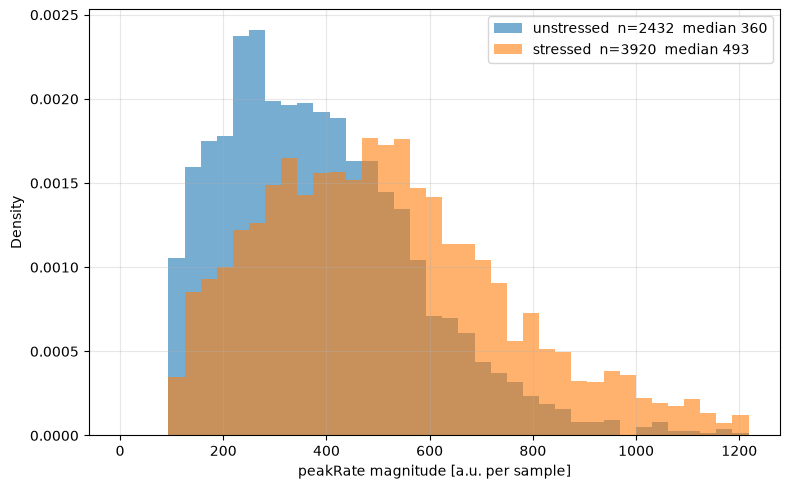

In [18]:
mags_str, mags_uns = [], []
for i, ch in enumerate(chapters):
    with open(os.path.join(ROOT, "audiobooks", f"{ch}_annotations.json")) as f:
        ph = json.load(f)["phones"]

    vows = [(p["start"], p["label"][-1]) for p in ph
            if p["label"].rstrip("012") in VOWELS and p["label"][-1] in "012"]
    if not vows:
        continue
    vt = np.array([v[0] for v in vows])
    vs = np.array([v[1] for v in vows])

    for k in np.flatnonzero(peakrates[i]):
        t = k / FS
        j = np.argmin(np.abs(vt - t))
        if abs(vt[j] - t) > 0.05:          # only events clearly on a vowel
            continue
        (mags_str if vs[j] == "1" else mags_uns).append(peakrates[i][k])

mags_str, mags_uns = np.array(mags_str), np.array(mags_uns)
d = (mags_str.mean() - mags_uns.mean()) / np.sqrt((mags_str.var() + mags_uns.var()) / 2)

plt.figure(figsize=(8, 5))
bins = np.linspace(0, np.percentile(np.r_[mags_str, mags_uns], 99), 40)
plt.hist(mags_uns, bins=bins, alpha=0.6, density=True,
         label=f'unstressed  n={len(mags_uns)}  median {np.median(mags_uns):.0f}')
plt.hist(mags_str, bins=bins, alpha=0.6, density=True,
         label=f'stressed  n={len(mags_str)}  median {np.median(mags_str):.0f}')
plt.xlabel('peakRate magnitude [a.u. per sample]'); plt.ylabel('Density')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "pr_stress.pdf"), bbox_inches="tight")

print(f"stressed    n={len(mags_str):5d}  mean {mags_str.mean():7.1f}")
print(f"unstressed  n={len(mags_uns):5d}  mean {mags_uns.mean():7.1f}")
print(f"d' = {d:.2f}   (published: 1.06)")

In [19]:
# --- peakRate and the envelope in a joint model  ---
alphas_j = np.logspace(0, 8, 17)          # same grid as 06
fc3, fc5 = ch_names.index('FC3'), ch_names.index('FC5')

env_z = [zscore(envs[i][:len(prs[i])]) for i in range(15)]

def lag_multi(feats, eeg, lags):
    """Lagged copies of several features for one chapter, edge samples discarded."""
    n = len(feats[0])
    t0, t1 = lags.max(), n + lags.min()
    X = np.vstack([f[t0 - L : t1 - L] for f in feats for L in lags])
    return X, eeg[:, t0:t1]

def design_multi(features, parts):
    Xs, Ys = zip(*(lag_multi([f[i] for f in features], eegs[i], lags) for i in parts))
    return np.hstack(Xs), np.hstack(Ys)

def evaluate(features, name):
    Xtr, Ytr = design_multi(features, train_parts)
    Xva, Yva = design_multi(features, val_parts)
    Xte, Yte = design_multi(features, test_parts)
    G, C = Xtr @ Xtr.T, Xtr @ Ytr.T
    I = np.eye(Xtr.shape[0])
    val_r, test_r = [], []
    for al in alphas_j:
        w = np.linalg.solve(G + al * I, C)
        pv, pt = Xva.T @ w, Xte.T @ w
        val_r.append([pearsonr(pv[:, c], Yva[c])[0] for c in range(63)])
        test_r.append([pearsonr(pt[:, c], Yte[c])[0] for c in range(63)])
    val_r, test_r = np.array(val_r), np.array(test_r)
    best = val_r.argmax(axis=0)                  # alpha chosen per channel on validation
    rt = test_r[best, np.arange(63)]             # scored on test
    print(f"{name:<22} test mean {rt.mean():.4f}   FC3 {rt[fc3]:.4f}   FC5 {rt[fc5]:.4f}")
    return rt

r_env  = evaluate([env_z],      "envelope only")
r_pr   = evaluate([prs],        "peakRate only")
r_both = evaluate([env_z, prs], "envelope + peakRate")

gain = r_both - r_env
print(f"\ngain from adding peakRate   FC3 {gain[fc3]:+.4f}   FC5 {gain[fc5]:+.4f}   "
      f"mean {gain.mean():+.4f}   channels improved {(gain > 0).sum()} of 63")

envelope only          test mean 0.0415   FC3 0.0650   FC5 0.0899
peakRate only          test mean 0.0351   FC3 0.0929   FC5 0.0830
envelope + peakRate    test mean 0.0452   FC3 0.0808   FC5 0.0947

gain from adding peakRate   FC3 +0.0159   FC5 +0.0048   mean +0.0037   channels improved 46 of 63


In [20]:
# does magnitude add to event timing? Binary versus magnitude-weighted train ---
# alpha selected per channel on validation, as for every accuracy comparison 
prs_bin = [zscore((peakrates[i][:len(prs[i])] > 0).astype(float)) for i in range(15)]

r_bin = evaluate([prs_bin], "timing only (binary)")
r_mag = r_pr                                  # magnitude-weighted train, from the cell above

print(f"timing only (binary)   mean {r_bin.mean():.4f}   {ch_names[best]} {r_bin[best]:.4f}")
print(f"timing + magnitude     mean {r_mag.mean():.4f}   {ch_names[best]} {r_mag[best]:.4f}")

timing only (binary)   test mean 0.0330   FC3 0.0947   FC5 0.0877
timing only (binary)   mean 0.0330   FC5 0.0877
timing + magnitude     mean 0.0351   FC5 0.0830


loaded 200 permutations from cache
 FC5  observed +0.0048   null mean -0.0003   95th +0.0008   p = 0.0100
mean  observed +0.0037   null mean -0.0010   95th +0.0004   p = 0.0050


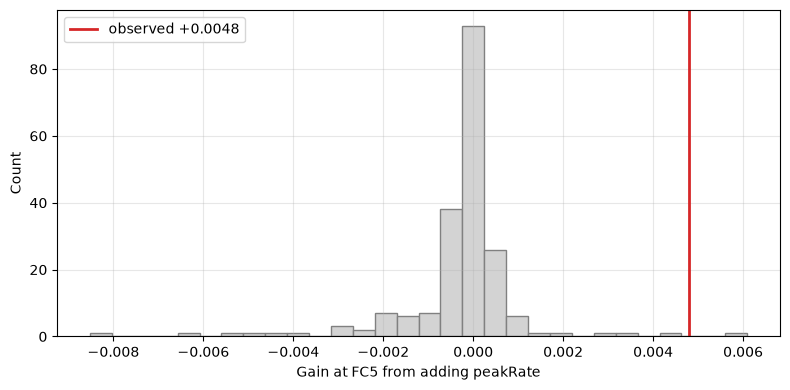

In [21]:
# --- Circular-shift null for the gain from adding peakRate ---
import contextlib, io

CACHE = os.path.join(P05, "cache")
os.makedirs(CACHE, exist_ok=True)
RECOMPUTE = False          # set True to force a rerun
N_PERM = 200
rng = np.random.default_rng(0)

def quiet(features):
    with contextlib.redirect_stdout(io.StringIO()):
        return evaluate(features, "")

cache_file = os.path.join(
    CACHE, f"null_peakrate_gain_n{N_PERM}_a{len(alphas_j)}_l{len(lags)}_s10.npy")

if os.path.exists(cache_file) and not RECOMPUTE:
    null_gain = np.load(cache_file)
    print(f"loaded {len(null_gain)} permutations from cache")
else:
    null_gain = []
    for j in range(N_PERM):
        shifted = [np.roll(prs[i], rng.integers(10*FS, len(prs[i]) - 10*FS))
                   for i in range(15)]
        null_gain.append(quiet([env_z, shifted]) - r_env)
        if (j + 1) % 25 == 0:
            print(f"  {j+1}/{N_PERM}")
    null_gain = np.array(null_gain)              # (N_PERM, 63)
    np.save(cache_file, null_gain)
    print(f"computed and saved to {os.path.basename(cache_file)}")

for name, obs, null in [(ch_names[best], gain[best], null_gain[:, best]),
                        ("mean", gain.mean(), null_gain.mean(axis=1))]:
    p = ((null >= obs).sum() + 1) / (N_PERM + 1)
    print(f"{name:>4}  observed {obs:+.4f}   null mean {null.mean():+.4f}   "
          f"95th {np.percentile(null, 95):+.4f}   p = {p:.4f}")

plt.figure(figsize=(8, 4))
plt.hist(null_gain[:, best], bins=30, color='lightgrey', edgecolor='grey')
plt.axvline(gain[best], c='tab:red', lw=2, label=f'observed {gain[best]:+.4f}')
plt.xlabel(f'Gain at {ch_names[best]} from adding peakRate'); plt.ylabel('Count')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(os.path.join(FIG, "pr_gain_null.pdf"), bbox_inches="tight")

corrected threshold +0.0152: C3 +0.0185, C4 +0.0252, FC1 +0.0405, FC2 +0.0359, FC3 +0.0159, FC4 +0.0207, FCz +0.0504


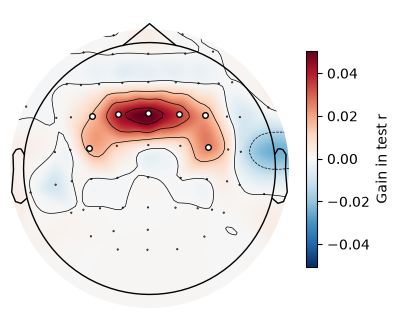

In [22]:
# where does peakRate add to the envelope? ---
thr_g = np.percentile(null_gain.max(axis=1), 95)
sig_g = gain > thr_g
print(f"corrected threshold {thr_g:+.4f}: "
      + ", ".join(f"{ch_names[k]} {gain[k]:+.4f}" for k in np.flatnonzero(sig_g)))

vg = np.abs(gain).max()
fig, ax = plt.subplots(figsize=(4.5, 4))
im, _ = mne.viz.plot_topomap(gain, info, axes=ax, cmap='RdBu_r', vlim=(-vg, vg), mask=sig_g, show=False)
cbar = fig.colorbar(im, ax=ax, shrink=0.7)
cbar.set_label('Gain in test r')
plt.savefig(os.path.join(FIG, "pr_joint_gain.pdf"), bbox_inches="tight")

In [23]:
# --- Published detection rule: one event per envelope cycle ---
SILENCE = {"sil", "sp", "spn", ""}

def cycle_events(i):
    """One event per envelope cycle: the steepest rise between successive troughs."""
    env_s = filtfilt(b_lp, a_lp, envs[i])
    troughs, _ = find_peaks(-env_s)
    ev = np.zeros(len(envs[i]))
    for t_a, t_b in zip(troughs[:-1], troughs[1:]):
        seg = derivs[i][t_a:t_b]
        if seg.max() > 0:
            k = t_a + seg.argmax()
            ev[k] = derivs[i][k]
    return ev

cycles = [cycle_events(i) for i in range(15)]

def phones(ch):
    with open(os.path.join(ROOT, "audiobooks", f"{ch}_annotations.json")) as f:
        return json.load(f)["phones"]

def alignment(events):
    d_v, d_c = [], []
    for i, ch in enumerate(chapters):
        ph = phones(ch)
        vow = np.array([p["start"] for p in ph if p["label"].rstrip("012") in VOWELS])
        con = np.array([p["start"] for p in ph
                        if p["label"].strip().lower() not in SILENCE
                        and p["label"].rstrip("012") not in VOWELS])
        for k in np.flatnonzero(events[i]):
            t = k / FS
            d_v.append((vow[np.argmin(np.abs(vow - t))] - t) * 1000)
            d_c.append((con[np.argmin(np.abs(con - t))] - t) * 1000)
    d_v, d_c = np.array(d_v), np.array(d_c)
    return d_v.std(), (np.abs(d_v) < 50).mean() * 100, (np.abs(d_c) < 50).mean() * 100

def stress_dprime(events):
    s, u = [], []
    for i, ch in enumerate(chapters):
        vows = [(p["start"], p["label"][-1]) for p in phones(ch)
                if p["label"].rstrip("012") in VOWELS and p["label"][-1] in "012"]
        vt, vs = np.array([v[0] for v in vows]), np.array([v[1] for v in vows])
        for k in np.flatnonzero(events[i]):
            j = np.argmin(np.abs(vt - k / FS))
            if abs(vt[j] - k / FS) <= 0.05:
                (s if vs[j] == "1" else u).append(events[i][k])
    s, u = np.array(s), np.array(u)
    return (s.mean() - u.mean()) / np.sqrt((s.var() + u.var()) / 2)

ci = best
win = (t_ep > 30) & (t_ep < 150)

n_sil = sum(1 for ch in chapters for p in phones(ch)
            if p["label"].strip().lower() in SILENCE)
print(f"non-phone intervals (silence and unrecognised speech): {n_sil}\n")

for name, ev in [("threshold", peakrates), ("one per cycle", cycles)]:
    rates = [(ev[i] > 0).sum() / (len(envs[i]) / FS) for i in range(15)]
    sd, v50, c50 = alignment(ev)
    peak = erp_at(ev, ci).mean(axis=0)[win].max()
    print(f"{name:<14} {min(rates):.2f}-{max(rates):.2f} per s   vowel SD {sd:5.1f} ms   "
          f"vowel <50 ms {v50:4.1f}%   consonant <50 ms {c50:4.1f}%   "
          f"difference {v50 - c50:4.1f} pts   d' {stress_dprime(ev):.2f}   "
          f"{ch_names[ci]} peak 30-150 ms {peak:.3f} µV")

non-phone intervals (silence and unrecognised speech): 840

threshold      3.23-3.65 per s   vowel SD  56.9 ms   vowel <50 ms 77.6%   consonant <50 ms 48.6%   difference 29.0 pts   d' 0.60   FC5 peak 30-150 ms 0.184 µV
one per cycle  5.55-6.09 per s   vowel SD 221.3 ms   vowel <50 ms 52.6%   consonant <50 ms 39.0%   difference 13.6 pts   d' 0.59   FC5 peak 30-150 ms 0.017 µV
